In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

from itertools import chain

# Parts of the code are modifications of Pytorch's AdamW optimizer
# Parts of the code are modifications of code from https://github.com/jiaweizzhao/GaLore/blob/master/galore_torch/galore_projector.py


class SOAP(optim.Optimizer):
    """
    Implements SOAP algorithm (https://arxiv.org/abs/2409.11321).

    Parameters:
        params (`Iterable[nn.parameter.Parameter]`):
            Iterable of parameters to optimize or dictionaries defining parameter groups.
        lr (`float`, *optional*, defaults to 0.003):
            The learning rate to use.
        betas (`Tuple[float,float]`, *optional*, defaults to `(0.95, 0.95)`):
            Adam's betas parameters (b1, b2).
        shampoo_beta (`float`, *optional*, defaults to -1):
            If >= 0, use this beta for the preconditioner (L and R in paper, state['GG'] below) moving average instead of betas[1].
        eps (`float`, *optional*, defaults to 1e-08):
            Adam's epsilon for numerical stability.
        weight_decay (`float`, *optional*, defaults to 0.01): weight decay coefficient.
        precondition_frequency (`int`, *optional*, defaults to 10):
            How often to update the preconditioner.
        max_precond_dim (`int`, *optional*, defaults to 10000):
            Maximum dimension of the preconditioner.
            Set to 10000, so that we exclude most common vocab sizes while including layers.
        merge_dims (`bool`, *optional*, defaults to `False`):
            Whether or not to merge dimensions of the preconditioner.
        precondition_1d (`bool`, *optional*, defaults to `False`):
            Whether or not to precondition 1D gradients.
        normalize_grads (`bool`, *optional*, defaults to `False`):
            Whether or not to normalize gradients per layer. 
            Helps at large precondition_frequency (~100 in our experiments), 
            but hurts performance at small precondition_frequency (~10 in our experiments).
        data_format (`str`, *optional*, defaults to `channels_first`):
            Data format of the input for convolutional layers.
            Should be "channels_last" for data_format of NHWC and "channels_first" for NCHW.
        correct_bias (`bool`, *optional*, defaults to `True`):
            Whether or not to use bias correction in Adam.
    """

    def __init__(
        self,
        params,
        lr: float = 3e-3,
        betas=(0.95, 0.95),
        shampoo_beta: float= -1,
        eps: float = 1e-8,
        weight_decay: float = 0.01,
        precondition_frequency: int=10,
        max_precond_dim: int=10000, # 
        merge_dims: bool = False, # Merge dimensions till the product of the dimensions is less than or equal to max_precond_dim.
        precondition_1d: bool = False,
        normalize_grads: bool = False,
        data_format: str = "channels_first",
        correct_bias: bool = True,
    ):
        defaults = {
            "lr": lr,
            "betas": betas,
            "shampoo_beta": shampoo_beta,
            "eps": eps,
            "weight_decay": weight_decay,
            "precondition_frequency": precondition_frequency,
            "max_precond_dim": max_precond_dim,
            "merge_dims": merge_dims,
            "precondition_1d": precondition_1d,
            "normalize_grads": normalize_grads,
            "correct_bias": correct_bias,
        }
        super().__init__(params, defaults)
        self._data_format = data_format
        
    def merge_dims(self, grad, max_precond_dim):
        """
        Merges dimensions of the gradient tensor till the product of the dimensions is less than or equal to max_precond_dim.
        """
        assert self._data_format in ["channels_first", "channels_last"]
        if self._data_format == "channels_last" and grad.dim() == 4:
            grad = grad.permute(0, 3, 1, 2)
        shape = grad.shape
        new_shape = []
        
        curr_shape = 1
        for sh in shape:
            temp_shape = curr_shape * sh
            if temp_shape > max_precond_dim:
                if curr_shape > 1:
                    new_shape.append(curr_shape)
                    curr_shape = sh
                else:
                    new_shape.append(sh)
                    curr_shape = 1
            else:
                curr_shape = temp_shape
        
        if curr_shape > 1 or len(new_shape)==0:
            new_shape.append(curr_shape)
        
        new_grad = grad.reshape(new_shape)
        return new_grad               

    @torch.no_grad()
    def step(self, closure = None):
        """
        Performs a single optimization step.

        Arguments:
            closure (`Callable`, *optional*): A closure that reevaluates the model and returns the loss.
        """
        if closure is None:
            loss = None
        else:
            loss = closure()
        
        for group in self.param_groups:
            for p in group["params"]:
                if p.grad is None:
                    continue
                grad = p.grad

                state = self.state[p]
                
                if "step" not in state:
                    state["step"] = 0 
                    
                # State initialization
                if "exp_avg" not in state:
                    # Exponential moving average of gradient values
                    state["exp_avg"] = torch.zeros_like(grad)
                    # Exponential moving average of squared gradient values
                    state["exp_avg_sq"] = torch.zeros_like(grad)
                
                if 'Q' not in state:
                    self.init_preconditioner(
                        grad,
                        state,
                        precondition_frequency=group['precondition_frequency'],
                        precondition_1d=group['precondition_1d'],
                        shampoo_beta=(group['shampoo_beta'] if group['shampoo_beta'] >= 0 else group["betas"][1]),
                        max_precond_dim=group['max_precond_dim'],
                        merge_dims=group["merge_dims"],
                    )
                    self.update_preconditioner(grad, state,
                                               max_precond_dim=group['max_precond_dim'],
                                               merge_dims=group["merge_dims"],
                                               precondition_1d=group["precondition_1d"])
                    continue # first step is skipped so that we never use the current gradients in the projection.
                
                # Projecting gradients to the eigenbases of Shampoo's preconditioner 
                # i.e. projecting to the eigenbases of matrices in state['GG']
                grad_projected = self.project(grad, state, merge_dims=group["merge_dims"], 
                                              max_precond_dim=group['max_precond_dim'])

                exp_avg, exp_avg_sq = state["exp_avg"], state["exp_avg_sq"]
                beta1, beta2 = group["betas"]

                state["step"] += 1

                # Decay the first and second moment running average coefficient
                # In-place operations to update the averages at the same time
                exp_avg.mul_(beta1).add_(grad_projected, alpha=(1.0 - beta1))
                exp_avg_sq.mul_(beta2).add_(grad_projected.square(), alpha=(1.0 - beta2))

                denom = exp_avg_sq.sqrt().add_(group["eps"])
                
                # Projecting the exponential moving average of gradients to the eigenbases of Shampoo's preconditioner 
                # i.e. projecting to the eigenbases of matrices in state['GG']
                # exp_avg_projected = self.project(exp_avg, state, merge_dims=group["merge_dims"],
                #                                  max_precond_dim=group['max_precond_dim'])
                exp_avg_projected = exp_avg
                
                step_size = group["lr"]
                if group["correct_bias"]:
                    bias_correction1 = 1.0 - beta1 ** (state["step"])
                    bias_correction2 = 1.0 - beta2 ** (state["step"])
                    step_size = step_size * (bias_correction2 ** .5) / bias_correction1

                # Projecting back the preconditioned (by Adam) exponential moving average of gradients
                # to the original space
                norm_grad = self.project_back(exp_avg_projected / denom, state, merge_dims=group["merge_dims"],
                                                 max_precond_dim=group['max_precond_dim'])

                if group["normalize_grads"]:
                    norm_grad = norm_grad / (1e-30+torch.mean(norm_grad**2)**0.5)
                
                p.add_(norm_grad, alpha=-step_size)
                

                # From AdamW code: Just adding the square of the weights to the loss function is *not*
                # the correct way of using L2 regularization/weight decay with Adam,
                # since that will interact with the m and v parameters in strange ways.
                #
                # Instead we want to decay the weights in a manner that doesn't interact
                # with the m/v parameters. This is equivalent to adding the square
                # of the weights to the loss with plain (non-momentum) SGD.
                # Add weight decay at the end (fixed version)
                if group["weight_decay"] > 0.0:
                    p.add_(p, alpha=(-group["lr"] * group["weight_decay"]))
                    
                # Update is done after the gradient step to avoid using current gradients in the projection.
                self.update_preconditioner(grad, state, 
                                               max_precond_dim=group['max_precond_dim'],
                                               merge_dims=group["merge_dims"],
                                               precondition_1d=group["precondition_1d"])
        
        return loss
    
    def init_preconditioner(self, grad, state, precondition_frequency=10, 
                            shampoo_beta=0.95, max_precond_dim=10000, precondition_1d=False,
                            merge_dims=False):
        """
        Initializes the preconditioner matrices (L and R in the paper).
        """
        state['GG'] = [] # Will hold all the preconditioner matrices (L and R in the paper).
        if grad.dim() == 1:
            if not precondition_1d or grad.shape[0] > max_precond_dim:
                state['GG'].append([])
            else:
                state['GG'].append(torch.zeros(grad.shape[0], grad.shape[0], device=grad.device))
        else:
            if merge_dims:
                grad = self.merge_dims(grad, max_precond_dim)

            for sh in grad.shape:
                if sh > max_precond_dim:
                    state['GG'].append([])
                else:
                    state['GG'].append(torch.zeros(sh, sh, device=grad.device))
                    
        state['Q'] = None # Will hold all the eigenbases of the preconditioner.
        state['precondition_frequency'] = precondition_frequency
        state['shampoo_beta'] = shampoo_beta          
        
    def project(self, grad, state, merge_dims=False, max_precond_dim=10000):
        """
        Projects the gradient to the eigenbases of the preconditioner.
        """
        original_shape = grad.shape
        if merge_dims:
            if grad.dim() == 4 and self._data_format == 'channels_last':
                permuted_shape = grad.permute(0, 3, 1, 2).shape
            grad = self.merge_dims(grad, max_precond_dim)

        for mat in state['Q']:
            if len(mat) > 0:
                grad = torch.tensordot(
                        grad,
                        mat,
                        dims=[[0], [0]],
                    )
            else:
                permute_order = list(range(1, len(grad.shape))) + [0]
                grad = grad.permute(permute_order)
        
        if merge_dims:
            if self._data_format == 'channels_last' and len(original_shape) == 4:
                grad = grad.reshape(permuted_shape).permute(0, 2, 3, 1)
            else:
                grad = grad.reshape(original_shape)
        return grad
        
    def update_preconditioner(self, grad, state, 
                              max_precond_dim=10000, merge_dims=False, precondition_1d=False):
        """
        Updates the preconditioner matrices and the eigenbases (L, R, Q_L, Q_R in the paper).
        """
        if state["Q"] is not None:
            state["exp_avg"] = self.project_back(state["exp_avg"], state, merge_dims=merge_dims, max_precond_dim=max_precond_dim)
        if grad.dim() == 1:
            if precondition_1d and grad.shape[0] <= max_precond_dim:
                state['GG'][0].lerp_(grad.unsqueeze(1) @ grad.unsqueeze(0), 1-state['shampoo_beta'])
        else:
            if merge_dims:
                new_grad = self.merge_dims(grad, max_precond_dim)
                for idx, sh in enumerate(new_grad.shape):
                    if sh <= max_precond_dim:
                        outer_product = torch.tensordot(
                                new_grad,
                                new_grad,
                                dims=[[*chain(range(idx), range(idx + 1, len(new_grad.shape)))]] * 2,
                            )
                        state['GG'][idx].lerp_(outer_product, 1-state['shampoo_beta'])
            else:
                for idx, sh in enumerate(grad.shape):
                    if sh <= max_precond_dim:
                        outer_product = torch.tensordot(
                                grad,
                                grad,
                                # Contracts across all dimensions except for k.
                                dims=[[*chain(range(idx), range(idx + 1, len(grad.shape)))]] * 2,
                            )
                        state['GG'][idx].lerp_(outer_product, 1-state['shampoo_beta'])
                     
        if state['Q'] is None:
            state['Q'] = self.get_orthogonal_matrix(state['GG'])
        if state['step'] > 0 and state['step'] % state['precondition_frequency'] == 0:
            state['Q'] = self.get_orthogonal_matrix_QR(state, max_precond_dim, merge_dims)
            # state['Q'] = self.get_fast_QR(state, max_precond_dim, merge_dims)             

        if state["step"] > 0:
            state["exp_avg"] = self.project(state["exp_avg"], state, merge_dims=merge_dims, max_precond_dim=max_precond_dim) 

    def project_back(self, grad, state, merge_dims=False, max_precond_dim=10000):
        """
        Projects the gradient back to the original space.
        """
        original_shape = grad.shape
        if merge_dims:
            if self._data_format == 'channels_last' and grad.dim() == 4:
                permuted_shape = grad.permute(0, 3, 1, 2).shape
            grad = self.merge_dims(grad, max_precond_dim)
        for mat in state['Q']:
            if len(mat) > 0:
                grad = torch.tensordot(
                        grad,
                        mat,
                        dims=[[0], [1]],
                    )
            else:
                permute_order = list(range(1, len(grad.shape))) + [0]
                grad = grad.permute(permute_order)
                
        if merge_dims:
            if self._data_format == 'channels_last' and len(original_shape) == 4:
                grad = grad.reshape(permuted_shape).permute(0, 2, 3, 1)
            else:
                grad = grad.reshape(original_shape)
        return grad
        

    def get_orthogonal_matrix(self, mat):
        """
        Computes the eigenbases of the preconditioner using torch.linalg.eigh decomposition.
        """
        matrix = []
        for m in mat:
            if len(m) == 0:
                matrix.append([])
                continue
            if m.data.dtype != torch.float:
                float_data = False
                original_type = m.data.dtype
                original_device = m.data.device
                matrix.append(m.data.float())
            else:
                float_data = True
                matrix.append(m.data)
        
        final = []
        for m in matrix:
            if len(m) == 0:
                final.append([])
                continue
            try:
                _, Q = torch.linalg.eigh(m+1e-30*torch.eye(m.shape[0], device=m.device))
            except:
                _, Q = torch.linalg.eigh(m.to(torch.float64)+1e-30*torch.eye(m.shape[0], device=m.device))
                Q = Q.to(m.dtype)
            Q = torch.flip(Q, [1])

            if not float_data:
                Q = Q.to(original_device).type(original_type)
            final.append(Q)
        return final
        

    def get_orthogonal_matrix_QR(self, state, max_precond_dim=10000, merge_dims=False):
        """
        Computes the eigenbases of the preconditioner using one round of power iteration 
        followed by torch.linalg.qr decomposition.
        """
        precond_list = state['GG']
        orth_list = state['Q']

        matrix = []
        orth_matrix = []
        for m,o in zip(precond_list, orth_list):
            if len(m) == 0:
                matrix.append([])
                orth_matrix.append([])
                continue
            if m.data.dtype != torch.float:
                float_data = False
                original_type = m.data.dtype
                original_device = m.data.device
                matrix.append(m.data.float())
                orth_matrix.append(o.data.float())
            else:
                float_data = True
                matrix.append(m.data.float())
                orth_matrix.append(o.data.float())
        
        orig_shape = state['exp_avg_sq'].shape
        if self._data_format == 'channels_last' and len(orig_shape) == 4:
            permuted_shape = state['exp_avg_sq'].permute(0, 3, 1, 2).shape
        if merge_dims:
            exp_avg_sq = self.merge_dims(state['exp_avg_sq'], max_precond_dim)
        else:
            exp_avg_sq = state['exp_avg_sq']
            
        final = []
        for ind, (m,o) in enumerate(zip(matrix, orth_matrix)):
            if len(m)==0:
                final.append([])
                continue
            est_eig = torch.diag(o.T @ m @ o)
            sort_idx = torch.argsort(est_eig, descending=True)
            exp_avg_sq = exp_avg_sq.index_select(ind, sort_idx)
            o = o[:,sort_idx]
            power_iter = m @ o
            Q, _ = torch.linalg.qr(power_iter)

            if not float_data:
                Q = Q.to(original_device).type(original_type)
            final.append(Q)
        
        if merge_dims:
            if self._data_format == 'channels_last' and len(orig_shape) == 4:
                exp_avg_sq = exp_avg_sq.reshape(permuted_shape).permute(0, 2, 3, 1)
            else:
                exp_avg_sq = exp_avg_sq.reshape(orig_shape)
                
        state['exp_avg_sq'] = exp_avg_sq
        return final
    
    

In [2]:
# ===============================
# CELL 1 — Imports
# ===============================

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

torch.manual_seed(42)
np.random.seed(42)


Using device: cuda


In [3]:
# ===============================
# CELL 2 — Physical Parameters
# ===============================

nu = 0.01               # viscosity
Re = 1/nu
T_final = 1.0

print("Reynolds number:", Re)

# Domain
x_min, x_max = 0.0, 2*np.pi
y_min, y_max = 0.0, 2*np.pi
t_min, t_max = 0.0, T_final


Reynolds number: 100.0


In [4]:
# ===============================
# CELL 3 — Exact Solution
# ===============================

def exact_solution(t, x, y, nu):
    u = -torch.cos(x)*torch.sin(y)*torch.exp(-2*nu*t)
    v =  torch.sin(x)*torch.cos(y)*torch.exp(-2*nu*t)
    p = -0.25*(torch.cos(2*x)+torch.cos(2*y))*torch.exp(-4*nu*t)
    return u, v, p


In [5]:
# ===============================
# CELL 4 — Neural Network
# ===============================

class PINN(nn.Module):
    def __init__(self, layers):
        super().__init__()
        self.layers = nn.ModuleList()
        self.activation = nn.Tanh()
        
        for i in range(len(layers)-1):
            self.layers.append(nn.Linear(layers[i], layers[i+1]))
            
    def forward(self, t, x, y):
        X = torch.cat([t, x, y], dim=1)
        for i in range(len(self.layers)-1):
            X = self.activation(self.layers[i](X))
        output = self.layers[-1](X)
        
        u = output[:,0:1]
        v = output[:,1:2]
        p = output[:,2:3]
        return u, v, p


In [6]:
# ===============================
# CELL 5 — Initialize Model
# ===============================

layers = [3,30,30,30,3]
model = PINN(layers).to(device)

print(model)


PINN(
  (layers): ModuleList(
    (0): Linear(in_features=3, out_features=30, bias=True)
    (1-2): 2 x Linear(in_features=30, out_features=30, bias=True)
    (3): Linear(in_features=30, out_features=3, bias=True)
  )
  (activation): Tanh()
)


In [7]:
# ===============================
# CELL 6 — Sampling Points
# ===============================

def sample_collocation(N):
    t = torch.rand(N,1)*(t_max-t_min) + t_min
    x = torch.rand(N,1)*(x_max-x_min) + x_min
    y = torch.rand(N,1)*(y_max-y_min) + y_min
    return t.to(device), x.to(device), y.to(device)


In [8]:
# ===============================
# CELL 7 — Physics Loss
# ===============================

mse = nn.MSELoss()

def pde_residual(model, t, x, y):
    
    t.requires_grad_(True)
    x.requires_grad_(True)
    y.requires_grad_(True)
    
    u, v, p = model(t, x, y)
    
    # First derivatives
    u_t = torch.autograd.grad(u, t, torch.ones_like(u), create_graph=True)[0]
    u_x = torch.autograd.grad(u, x, torch.ones_like(u), create_graph=True)[0]
    u_y = torch.autograd.grad(u, y, torch.ones_like(u), create_graph=True)[0]
    
    v_t = torch.autograd.grad(v, t, torch.ones_like(v), create_graph=True)[0]
    v_x = torch.autograd.grad(v, x, torch.ones_like(v), create_graph=True)[0]
    v_y = torch.autograd.grad(v, y, torch.ones_like(v), create_graph=True)[0]
    
    p_x = torch.autograd.grad(p, x, torch.ones_like(p), create_graph=True)[0]
    p_y = torch.autograd.grad(p, y, torch.ones_like(p), create_graph=True)[0]
    
    # Second derivatives
    u_xx = torch.autograd.grad(u_x, x, torch.ones_like(u_x), create_graph=True)[0]
    u_yy = torch.autograd.grad(u_y, y, torch.ones_like(u_y), create_graph=True)[0]
    
    v_xx = torch.autograd.grad(v_x, x, torch.ones_like(v_x), create_graph=True)[0]
    v_yy = torch.autograd.grad(v_y, y, torch.ones_like(v_y), create_graph=True)[0]
    
    # Residuals
    f_cont = u_x + v_y
    
    f_u = u_t + u*u_x + v*u_y + p_x - nu*(u_xx + u_yy)
    f_v = v_t + u*v_x + v*v_y + p_y - nu*(v_xx + v_yy)
    
    loss_f = mse(f_cont, torch.zeros_like(f_cont)) \
           + mse(f_u, torch.zeros_like(f_u)) \
           + mse(f_v, torch.zeros_like(f_v))
    
    return loss_f


In [9]:
# ===============================
# CELL 8 — Initial Condition
# ===============================

def initial_condition_loss(model, N_ic=1000):
    t = torch.zeros(N_ic,1).to(device)
    x = torch.rand(N_ic,1)*(x_max-x_min) + x_min
    y = torch.rand(N_ic,1)*(y_max-y_min) + y_min
    
    x = x.to(device)
    y = y.to(device)
    
    u_exact, v_exact, _ = exact_solution(t, x, y, nu)
    u_pred, v_pred, _ = model(t, x, y)
    
    loss_ic = mse(u_pred, u_exact) + mse(v_pred, v_exact)
    return loss_ic


In [10]:
# ===============================
# CELL 9 — Periodic Boundaries
# ===============================

def boundary_loss(model, N_bc=1000):
    
    t = torch.rand(N_bc,1)*(t_max-t_min) + t_min
    
    y = torch.rand(N_bc,1)*(y_max-y_min) + y_min
    x_left  = torch.zeros_like(y)
    x_right = torch.ones_like(y)*2*np.pi
    
    t = t.to(device)
    y = y.to(device)
    x_left = x_left.to(device)
    x_right = x_right.to(device)
    
    u_l, v_l, _ = model(t, x_left, y)
    u_r, v_r, _ = model(t, x_right, y)
    
    loss_bc = mse(u_l, u_r) + mse(v_l, v_r)
    
    return loss_bc


In [11]:
N_data = 2000

x_data = torch.rand(N_data, 1).to(device)
y_data = torch.rand(N_data, 1).to(device)
t_data = torch.rand(N_data, 1).to(device)

u_data_exact, v_data_exact, p_data_exact = exact_solution(x_data, y_data, t_data,nu)

u_data_exact = u_data_exact.to(device)
v_data_exact = v_data_exact.to(device)
p_data_exact = p_data_exact.to(device)



In [12]:
def data_loss(model):
    u_pred, v_pred, p_pred = model(x_data, y_data, t_data)

    loss_u = torch.mean((u_pred - u_data_exact)**2)
    loss_v = torch.mean((v_pred - v_data_exact)**2)

    return loss_u + loss_v


In [13]:
loss_history = []
loss_pde_history = []
loss_ic_history = []
loss_bc_history = []
loss_symmetry_history = []


In [14]:
def compute_loss():

    # PDE residual
    loss_f = pde_residual(model, t_f, x_f, y_f)

    # Initial condition
    loss_ic = initial_condition_loss(model, N_ic=300)

    # Boundary condition
    loss_bc = boundary_loss(model, N_bc=600)

    total_loss = loss_f + 2*loss_ic + loss_bc 

    return total_loss, loss_f, loss_ic, loss_bc


In [15]:
optimizer = SOAP(
    model.parameters(),
    lr=1e-3,
    betas=(0.95, 0.95),
    weight_decay=0.1,
    precondition_frequency=10
)


In [16]:
# ===============================
# CELL 10 — Training
# ===============================µ


epochs = 10000
N_f = 2000
t_f, x_f, y_f = sample_collocation(N_f)
for epoch in tqdm(range(epochs)):
    
    optimizer.zero_grad()

    total_loss, loss_f, loss_ic, loss_bc = compute_loss()


    total_loss.backward()
    optimizer.step()

    loss_history.append(total_loss.item())
    loss_pde_history.append(loss_f.item())
    loss_ic_history.append(loss_ic.item())
    loss_bc_history.append(loss_bc.item())

    if epoch % 500 == 0:
        print(f"Epoch {epoch}, "
              f"Total: {total_loss.item():.3e}, "
              f"PDE: {loss_f.item():.3e}, "
              f"IC: {loss_ic.item():.3e}, "
              f"BC: {loss_bc.item():.3e}")


  0%|          | 3/10000 [00:00<26:49,  6.21it/s]  

Epoch 0, Total: 1.140e+00, PDE: 1.020e-03, IC: 5.607e-01, BC: 1.740e-02


  5%|▌         | 506/10000 [00:11<03:26, 45.90it/s]

Epoch 500, Total: 2.564e-01, PDE: 2.249e-02, IC: 1.111e-01, BC: 1.163e-02


 10%|█         | 1006/10000 [00:23<03:19, 45.02it/s]

Epoch 1000, Total: 9.779e-03, PDE: 4.277e-03, IC: 2.206e-03, BC: 1.090e-03


... (31 outputs left out)

Epoch 9000, Total: 5.557e-05, PDE: 2.861e-05, IC: 9.287e-06, BC: 8.391e-06


 95%|█████████▌| 9506/10000 [03:33<00:10, 47.00it/s]

Epoch 9500, Total: 6.326e-05, PDE: 2.706e-05, IC: 1.179e-05, BC: 1.262e-05


100%|██████████| 10000/10000 [03:43<00:00, 44.65it/s]


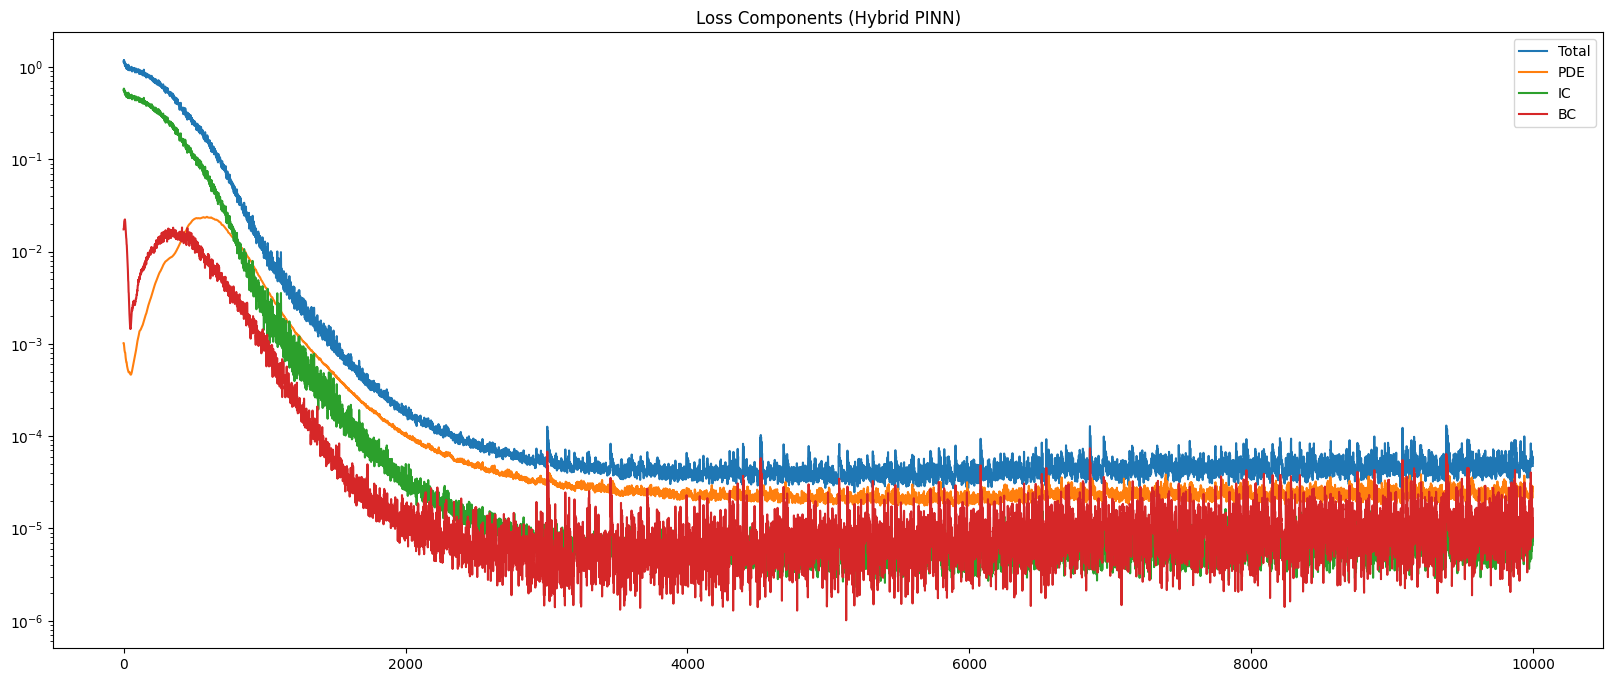

In [17]:
plt.figure(figsize=(20,8))
plt.plot(loss_history, label="Total")
plt.plot(loss_pde_history, label="PDE")
plt.plot(loss_ic_history, label="IC")
plt.plot(loss_bc_history, label="BC")
plt.yscale("log")
plt.legend()
plt.title("Loss Components (Hybrid PINN)")
plt.show()


In [18]:

# ===============================
# L-BFGS Refinement Stage
# ===============================

# Reduce collocation batch size for stability
N_f_lbfgs = 1000

optimizer_lbfgs = torch.optim.LBFGS(
    model.parameters(),
    lr=2.0,
    max_iter=5000,
    max_eval=5000,
    history_size=50,
    tolerance_grad=1e-9,
    tolerance_change=1e-9,
    line_search_fn="strong_wolfe"
)

print("Starting L-BFGS...")


def closure():
    optimizer_lbfgs.zero_grad()

    total_loss, loss_f, loss_ic, loss_bc = compute_loss()

    total_loss.backward()

    # Store
    loss_history.append(total_loss.item())
    loss_pde_history.append(loss_f.item())
    loss_ic_history.append(loss_ic.item())
    loss_bc_history.append(loss_bc.item())

    return total_loss

optimizer_lbfgs.step(closure)


Starting L-BFGS...


tensor(5.5606e-05, device='cuda:0', grad_fn=<AddBackward0>)

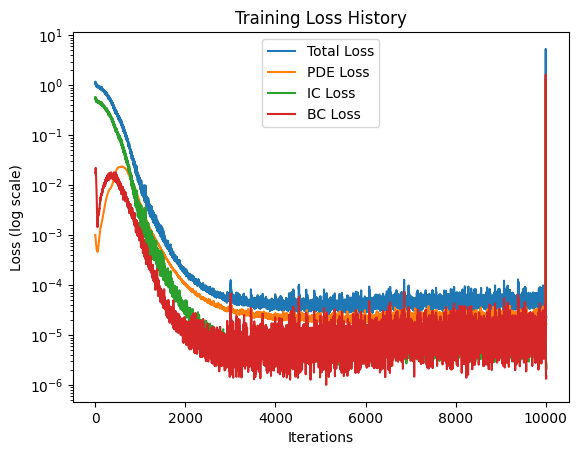

In [19]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(loss_history, label="Total Loss")
plt.plot(loss_pde_history, label="PDE Loss")
plt.plot(loss_ic_history, label="IC Loss")
plt.plot(loss_bc_history, label="BC Loss")
plt.yscale("log")
plt.legend()
plt.title("Training Loss History")
plt.xlabel("Iterations")
plt.ylabel("Loss (log scale)")
plt.show()


In [20]:
# ===============================
# CELL 11 — Evaluation Grid
# ===============================

N = 100
x = np.linspace(0, 2*np.pi, N)
y = np.linspace(0, 2*np.pi, N)
X, Y = np.meshgrid(x, y)

t_eval = torch.ones(N*N,1)*T_final
x_eval = torch.tensor(X.flatten(), dtype=torch.float32).reshape(-1,1)
y_eval = torch.tensor(Y.flatten(), dtype=torch.float32).reshape(-1,1)

t_eval = t_eval.to(device)
x_eval = x_eval.to(device)
y_eval = y_eval.to(device)

u_pred, v_pred, p_pred = model(t_eval, x_eval, y_eval)

u_pred = u_pred.detach().cpu().numpy().reshape(N,N)
v_pred = v_pred.detach().cpu().numpy().reshape(N,N)


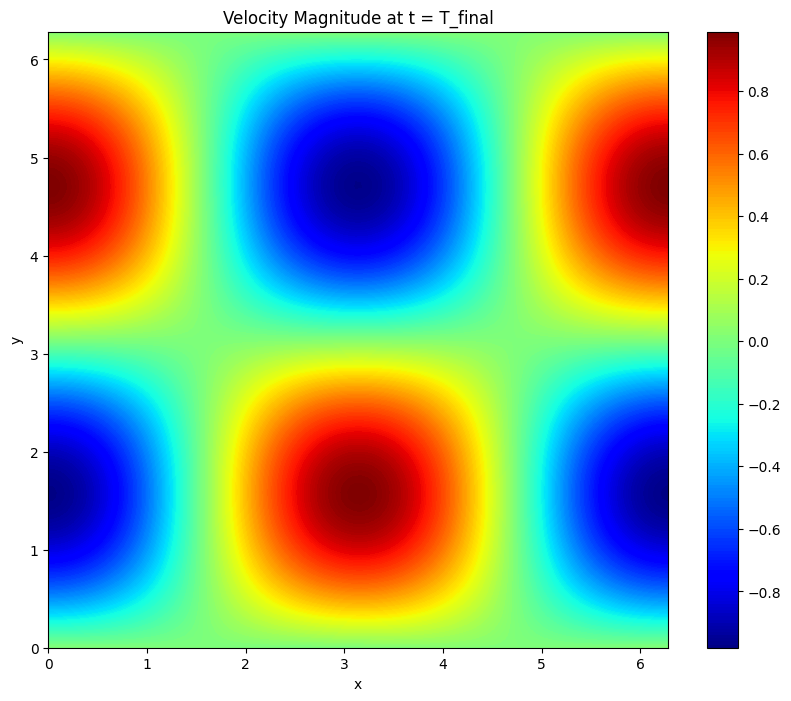

In [21]:
# ===============================
# CELL 12 — Plot Velocity Magnitude
# ===============================

velocity_mag = np.sqrt(u_pred**2 + v_pred**2)

plt.figure(figsize=(10,8))
plt.contourf(X, Y, u_pred, 200, cmap=cm.jet,vmin=-0.99,vmax=0.99)
plt.colorbar()
plt.title("Velocity Magnitude at t = T_final")
plt.xlabel("x")
plt.ylabel("y")
plt.show()


In [22]:
print(u_pred.min().item())
print(u_pred.max().item())


-0.9744418263435364
0.9876582026481628


In [23]:
u_exact = np.sin(X) * np.cos(Y) * np.exp(-2 * nu * T_final)

print("Exact min:", u_exact.min())
print("Exact max:", u_exact.max())


Exact min: -0.9800752934196816
Exact max: 0.9800752934196816


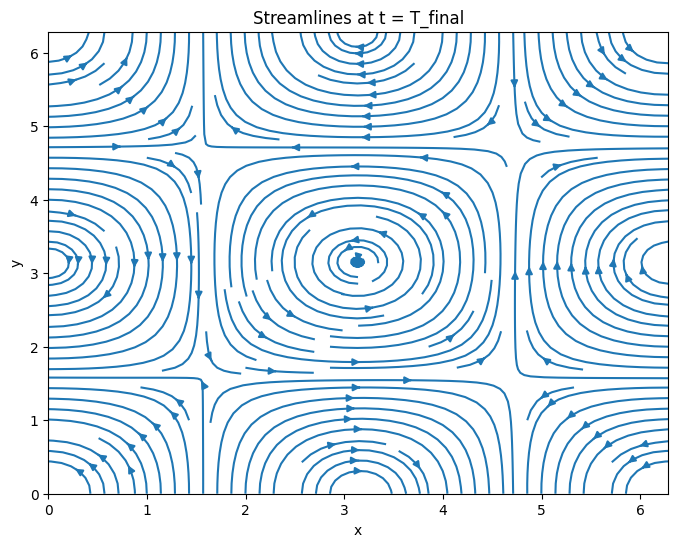

In [24]:
plt.figure(figsize=(8,6))
plt.streamplot(X, Y, u_pred, v_pred, density=1.5)
plt.title("Streamlines at t = T_final")
plt.xlabel("x")
plt.ylabel("y")
plt.show()


In [25]:
# ===============================
# CELL 14 — L2 Relative Error
# ===============================

def relative_l2(u_pred, u_exact):
    return np.linalg.norm(u_pred - u_exact) / np.linalg.norm(u_exact)


# Exact solution at T_final
u_exact, v_exact, _ = exact_solution(
    t_eval, x_eval, y_eval, nu
)

u_exact = u_exact.detach().cpu().numpy().reshape(N,N)
v_exact = v_exact.detach().cpu().numpy().reshape(N,N)

error_u = relative_l2(u_pred, u_exact)
error_v = relative_l2(v_pred, v_exact)

print("Relative L2 Error (u):", error_u)
print("Relative L2 Error (v):", error_v)


Relative L2 Error (u): 0.015670804
Relative L2 Error (v): 0.015749833


In [26]:
# ===============================
# CELL 15 — Energy Computation
# ===============================

dx = (2*np.pi)/(N-1)
dy = (2*np.pi)/(N-1)

def compute_energy(u, v):
    energy_density = 0.5 * (u**2 + v**2)
    return np.sum(energy_density) * dx * dy


In [27]:
# ===============================
# CELL 16 — Energy vs Time
# ===============================

time_points = np.linspace(0, T_final, 50)
energy_pred = []
energy_exact = []

for t_val in time_points:
    
    t_grid = torch.ones(N*N,1)*t_val
    t_grid = t_grid.to(device)
    
    u_pred_t, v_pred_t, _ = model(t_grid, x_eval, y_eval)
    u_pred_t = u_pred_t.detach().cpu().numpy().reshape(N,N)
    v_pred_t = v_pred_t.detach().cpu().numpy().reshape(N,N)
    
    # Exact
    u_exact_t, v_exact_t, _ = exact_solution(
        t_grid, x_eval, y_eval, nu
    )
    u_exact_t = u_exact_t.detach().cpu().numpy().reshape(N,N)
    v_exact_t = v_exact_t.detach().cpu().numpy().reshape(N,N)
    
    energy_pred.append(compute_energy(u_pred_t, v_pred_t))
    energy_exact.append(compute_energy(u_exact_t, v_exact_t))


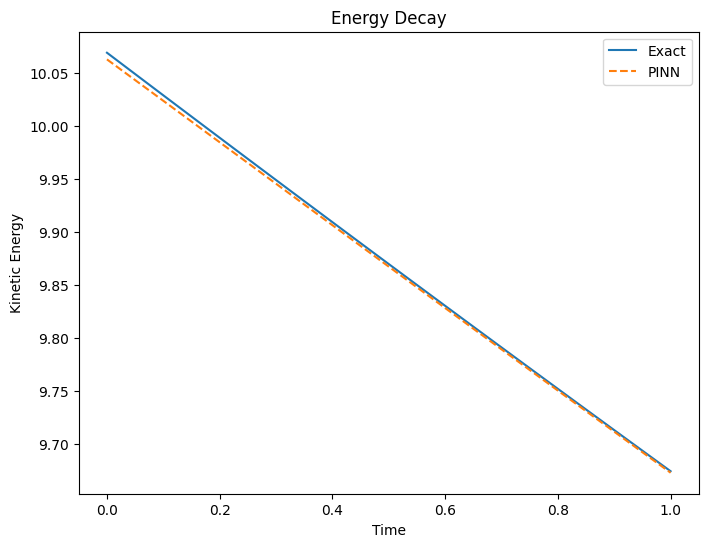

In [28]:
# ===============================
# CELL 17 — Plot Energy
# ===============================

plt.figure(figsize=(8,6))
plt.plot(time_points, energy_exact, label="Exact")
plt.plot(time_points, energy_pred, "--", label="PINN")
plt.xlabel("Time")
plt.ylabel("Kinetic Energy")
plt.title("Energy Decay")
plt.legend()
plt.show()


In [29]:


# ===============================
# CELL 18 — Error vs Time
# ===============================

error_time = []

for i, t_val in enumerate(time_points):
    
    t_grid = torch.ones(N*N,1)*t_val
    t_grid = t_grid.to(device)
    
    u_pred_t, v_pred_t, _ = model(t_grid, x_eval, y_eval)
    u_pred_t = u_pred_t.detach().cpu().numpy().reshape(N,N)
    
    u_exact_t, _, _ = exact_solution(
        t_grid, x_eval, y_eval, nu
    )
    u_exact_t = u_exact_t.detach().cpu().numpy().reshape(N,N)
    
    error_time.append(relative_l2(u_pred_t, u_exact_t))


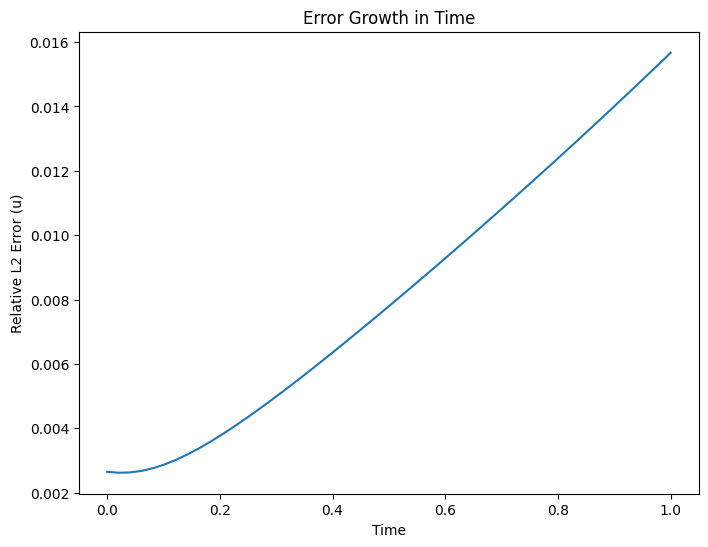

In [30]:

plt.figure(figsize=(8,6))
plt.plot(time_points, error_time)
plt.xlabel("Time")
plt.ylabel("Relative L2 Error (u)")
plt.title("Error Growth in Time")
plt.show()
